# interpolation_grid_grid 方法说明

将源格点场重采样到目标水平网格。包内两类入口：

| 系列 | 插件 | 典型用途 |
| --- | --- | --- |
| 等距经纬插值（InterpGg*） | `InterpGgLinear` / `Nearest` / `Cubic` | 等距经纬、融合/背景对齐；越界用 `outer_value` |
| LandSea | `InterpGgLandSea`（及 `InterpGgLandSea2`） | RGI / `*-2` 重网格；可选海陆掩码 |

在包根或本 `nbs/` 目录打开本 notebook 即可运行示例（依赖 `meteva_base`、`resource/data`）。

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import meteva_base as meb
from meteva_base.tool.color_tools import get_cmap_and_clevs_by_element_name
from meteva_base.tool.plot_tools import pcolormesh_2d_grid

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

PACKAGE_ROOT = Path.cwd().resolve()
if PACKAGE_ROOT.name == "nbs":
    PACKAGE_ROOT = PACKAGE_ROOT.parent
DATA_DIR = PACKAGE_ROOT / "resource" / "data"

src_s, root_s = str(PACKAGE_ROOT / "src"), str(PACKAGE_ROOT)
for p in (src_s, root_s):
    if p in sys.path:
        sys.path.remove(p)
sys.path.insert(0, src_s)
sys.path.insert(0, root_s)

from interp_gg_cubic_plugin import InterpGgCubic
from interp_gg_landsea_plugin import InterpGgLandSea
from interp_gg_linear_plugin import InterpGgLinear
from interp_gg_nearest_plugin import InterpGgNearest


d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## 1. 等距经纬插值（InterpGg*）：原理

接口统一为 `process(grd, grid)`：`grd` 为源六维场，`grid` 为目标 `meb.grid`（等距经纬）。

| 方法 | 原理 |
| --- | --- |
| **InterpGgLinear** | 目标点映射到源索引分数，取四邻点双线性加权 |
| **InterpGgNearest** | 索引四舍五入到最近源格点赋值 |
| **InterpGgCubic** | 对邻域 `p,q ∈ {-1,0,1,2}` 用三次核 `cubic_f` 加权 |

共同约定：

- 源经度跨满 360°（`iscycle`）时经度取模；**纬度越界仍须** `outer_value`。
- 非循环场经纬越界：先插重叠区，再 `expand_to_contain_another_grid` 填外区。
- `member` / `level` / `time` / `dtime` 继承源场；水平网格取自目标 `grid`。
- `attrs` 深拷贝自源场。

## 2. 等距经纬插值（InterpGg*）：参数

| 参数 | 位置 | 说明 |
| --- | --- | --- |
| `outer_value` | 构造 | 目标超出源域时的填充值；越界且未给则返回 `None` |
| `grd` | `process` | 源格点场 |
| `grid` | `process` | 目标网格信息（`glon` / `glat` 等） |

CLI（在包目录）：`python -m cli --module linear|nearest|cubic ...`，缺省读 `resource/conf.ini`。

## 3. InterpGg 使用示例

### 3.1 InterpGgLinear使用示例

In [2]:
# 源场：分辨率为1°
grid = meb.read_griddata_from_nc(str(DATA_DIR / "2026100900.024.nc"))
grd_in = grid.sel(lon=slice(101.0, 123.0), lat=slice(20.0, 38.0)) # 网格经纬裁剪
# 目标：略加密、落在源域内
target = meb.basicdata.grid([101.0, 123.0, 0.01], [20.0, 38.0, 0.01])

grd_out_linear = InterpGgLinear(outer_value=0.0).process(grd_in, target)
print(grd_out_linear)

<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 1801,
                           lon: 2201)> Size: 16MB
array([[[[[[19.8     , 19.699999, 19.599998, ..., 28.720001,
            28.710001, 28.7     ],
           [19.679998, 19.581999, 19.484   , ..., 28.702   ,
            28.691   , 28.68    ],
           [19.56    , 19.463999, 19.368   , ..., 28.684   ,
            28.672   , 28.66    ],
           ...,
           [-8.86    , -8.74    , -8.62    , ..., 19.4     ,
            19.4     , 19.4     ],
           [-8.93    , -8.8     , -8.67    , ..., 19.4     ,
            19.4     , 19.4     ],
           [-9.      , -8.86    , -8.72    , ..., 19.4     ,
            19.4     , 19.4     ]]]]]],
      shape=(1, 1, 1, 1, 1801, 2201), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 14kB 20.0 20.01 20.02 20.0

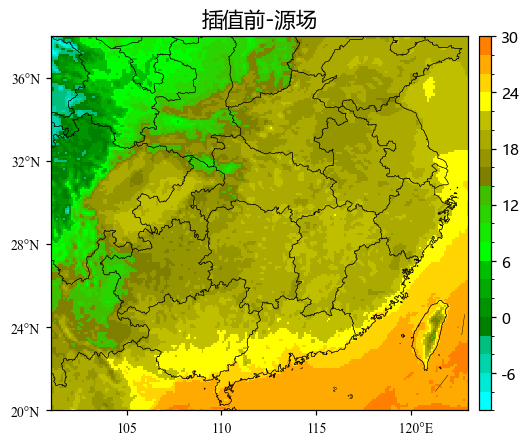

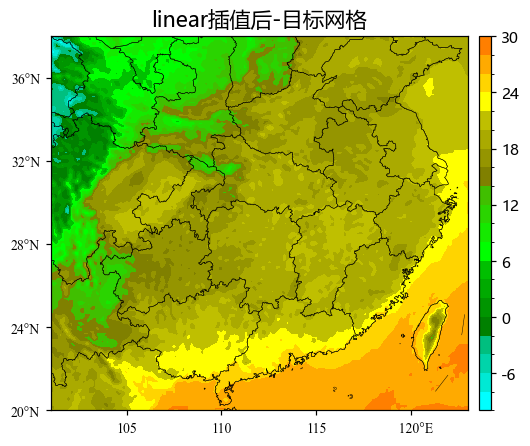

In [3]:
cmap, clevs = get_cmap_and_clevs_by_element_name("temp")
pcolormesh_2d_grid(
    grd_in, title="插值前-源场",
    cmap=cmap, clevs=clevs, dpi=110, show=True,
)
pcolormesh_2d_grid(
    grd_out_linear, title="linear插值后-目标网格",
    cmap=cmap, clevs=clevs, dpi=110, show=True,
)

### 3.2 InterpGgNearest使用示例

<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 1801,
                           lon: 2201)> Size: 16MB
array([[[[[[19.8, 19.8, 19.8, ..., 28.7, 28.7, 28.7],
           [19.8, 19.8, 19.8, ..., 28.7, 28.7, 28.7],
           [19.8, 19.8, 19.8, ..., 28.7, 28.7, 28.7],
           ...,
           [-9. , -9. , -9. , ..., 19.4, 19.4, 19.4],
           [-9. , -9. , -9. , ..., 19.4, 19.4, 19.4],
           [-9. , -9. , -9. , ..., 19.4, 19.4, 19.4]]]]]],
      shape=(1, 1, 1, 1, 1801, 2201), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 14kB 20.0 20.01 20.02 20.03 ... 37.98 37.99 38.0
  * lon      (lon) float64 18kB 101.0 101.0 101.0 101.0 ... 123.0 123.0 123.0
Attributes:
    units:        ℃
    model_var:    
    dtime_units:  hour
    level_type:   isobaric
    time_type:    UT
    time_bounds:  [0, 0]


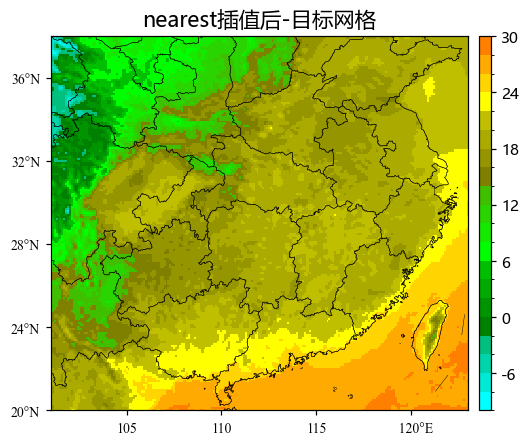

In [4]:
grd_out_nearest = InterpGgNearest(outer_value=0.0).process(grd_in, target)
print(grd_out_nearest)
pcolormesh_2d_grid(
    grd_out_nearest, title="nearest插值后-目标网格",
    cmap=cmap, clevs=clevs, dpi=110, show=True,
)

### 3.3 InterpGgCubic使用示例

<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 1801,
                           lon: 2201)> Size: 16MB
array([[[[[[19.8      , 19.71365  , 19.6192   , ..., 28.712002 ,
            28.705502 , 28.7      ],
           [19.70265  , 19.616886 , 19.523132 , ..., 28.70569  ,
            28.697622 , 28.69065  ],
           [19.5952   , 19.510159 , 19.41725  , ..., 28.697428 ,
            28.68772  , 28.679201 ],
           ...,
           [-8.8776   , -8.812468 , -8.735367 , ..., 19.396801 ,
            19.39835  , 19.4      ],
           [-8.9417   , -8.8695965, -8.784523 , ..., 19.3968   ,
            19.398352 , 19.4      ],
           [-9.       , -8.9213505, -8.828799 , ..., 19.3968   ,
            19.39835  , 19.4      ]]]]]],
      shape=(1, 1, 1, 1, 1801, 2201), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat

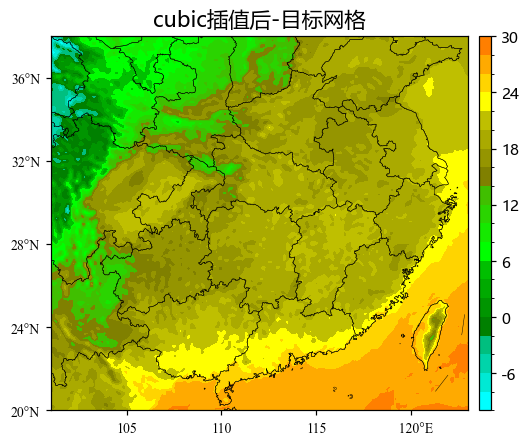

In [5]:
grd_out_cubic = InterpGgCubic(outer_value=0.0).process(grd_in, target)
print(grd_out_cubic)
pcolormesh_2d_grid(
    grd_out_cubic, title="cubic插值后-目标网格",
    cmap=cmap, clevs=clevs, dpi=110, show=True,
)

## 4. LandSea：原理

`InterpGgLandSea` 为统一入口，按 `regrid_mode` 分派：

| `regrid_mode` | 路径 | 掩码 |
| --- | --- | --- |
| `bilinear` / `nearest` | `RegularGridInterpolator`（scipy） | 否 |
| `nearest-with-mask` | 先最近邻，再 `AdjustLandSeaPoints` 订正 | 要源+目标掩码 |
| `bilinear-2` / `nearest-2` | `InterpGgLandSea2` 自研核 | 否 |
| `*-with-mask-2` | `InterpGgLandSea2`：插值时按海陆改邻点/权重 | 要源+目标掩码 |

**掩码约定**：`land_binary_mask`，陆=1、海=0。  
- 源掩码：构造参数 `landmask`。  
- 目标掩码：`process` 的第二参 `target_grid`（掩码模式下该场本身即目标掩码，并提供目标网格）。

`nearest-with-mask`：插值后再用邻域（`landmask_vicinity`，默认 25 km）内同类型最近点替换误取海/陆的点。  
`*-with-mask-2`：在四邻点阶段就按海陆筛选，不是纯后处理。

`extrapolation_mode` 仅作用于 scipy 路径；`*-2` 源域外固定填 NaN，且源场须为经纬度规则网格。业务请始终走 `InterpGgLandSea`（`*-2` 不必直接调 `InterpGgLandSea2`）。

## 5. LandSea：参数

### `InterpGgLandSea`

| 参数 | 说明 |
| --- | --- |
| `regrid_mode` | 见上表；默认 `bilinear` |
| `extrapolation_mode` | 仅 scipy 路径：`nan`（默认）/ `extrapolate` / `error`（别名 mask/nanmask → nan） |
| `landmask` | 源侧海陆掩码；`*-with-mask*` 必需 |
| `landmask_vicinity` | 同类型搜索半径（米），默认 `25000` |
| `process(data, target_grid, regridded_title=None)` | `data` 源场；`target_grid` 目标网格模板（掩码模式为目标掩码场） |

### `InterpGgLandSea2`（一般经 `InterpGgLandSea` 调用）

| 参数 | 说明 |
| --- | --- |
| `regrid_mode` | `bilinear-2` / `nearest-2` / `*-with-mask-2` |
| `vicinity_radius` | 同 `landmask_vicinity` |
| `process(data_in, data_in_mask, data_out_mask)` | 无掩码时 `data_in_mask` 可为 `None` |

CLI：`python -m cli.tran_regrid --input-path ... --target-grid-path ... [--land-sea-mask-path ...] --regrid-mode ...`

## 6. LandSea 使用示例（无掩码）

以预报场为源、HGT 子集为目标网格（仅取空间坐标）。

<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 1801,
                           lon: 2201)> Size: 16MB
array([[[[[[19.8     , 19.699999, 19.599998, ..., 28.720001,
            28.710001, 28.7     ],
           [19.679998, 19.581999, 19.484   , ..., 28.702   ,
            28.691   , 28.68    ],
           [19.56    , 19.463999, 19.368   , ..., 28.684   ,
            28.672   , 28.66    ],
           ...,
           [-8.86    , -8.74    , -8.62    , ..., 19.4     ,
            19.4     , 19.4     ],
           [-8.93    , -8.8     , -8.67    , ..., 19.4     ,
            19.4     , 19.4     ],
           [-9.      , -8.86    , -8.72    , ..., 19.4     ,
            19.4     , 19.4     ]]]]]],
      shape=(1, 1, 1, 1, 1801, 2201), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 14kB 20.0 20.01 20.02 20.0

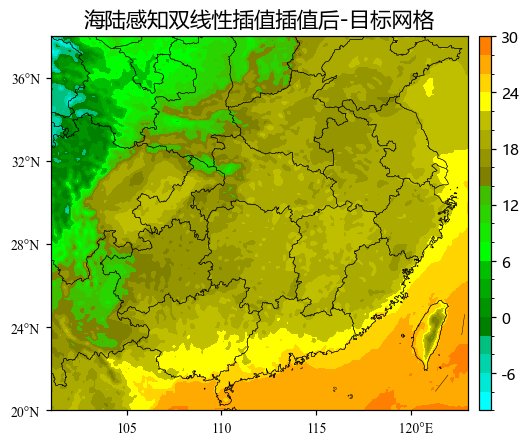

In [6]:
# grd_in / target_grid 为同域或可覆盖的格点场
target_grid = meb.grid_data(target)
grd_out_landsea_bilinear = InterpGgLandSea(
    regrid_mode="bilinear",
    extrapolation_mode="nan",
).process(grd_in, target_grid)
print(grd_out_landsea_bilinear)
pcolormesh_2d_grid(
    grd_out_landsea_bilinear, title="海陆感知双线性插值插值后-目标网格",
    cmap=cmap, clevs=clevs, dpi=110, show=True,
)

## 7. 选型建议

- **业务融合 / 背景对齐（meb 等距经纬）**：优先 `InterpGgLinear` / `Nearest` / `Cubic`，越界用 `outer_value`。
- **与 IMPROVER 海陆模式对齐**：`InterpGgLandSea`；需掩码时准备源、目标两份 `land_binary_mask`。
- 等距经纬、域内：InterpGgLinear 与 LandSea `bilinear` 数值接近；最近邻在格心附近可能有格点级差。
- 更多海陆细节见 `docs/interpolation_grid_grid.md`；数值对比见 `nbs/cmp_gg_vs_regrid.ipynb`。

## 8. CLI 使用示例

### 8.1 InterpolationGridGridCli

写出 → D:\workspace\test\00temp\interpolation_grid_grid\resource\data\cli_linear_out.m4
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 1801,
                           lon: 2201)> Size: 16MB
array([[[[[[19.8     , 19.699999, 19.599998, ..., 28.720001,
            28.710001, 28.7     ],
           [19.68    , 19.581999, 19.484   , ..., 28.702   ,
            28.691   , 28.68    ],
           [19.56    , 19.463999, 19.368   , ..., 28.684   ,
            28.672   , 28.66    ],
           ...,
           [-8.86    , -8.74    , -8.62    , ..., 19.4     ,
            19.4     , 19.4     ],
           [-8.93    , -8.8     , -8.67    , ..., 19.4     ,
            19.4     , 19.4     ],
           [-9.      , -8.86    , -8.72    , ..., 19.4     ,
            19.4     , 19.4     ]]]]]],
      shape=(1, 1, 1, 1, 1801, 2201), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09


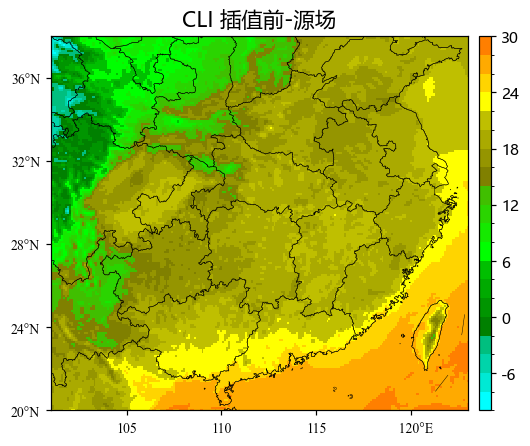

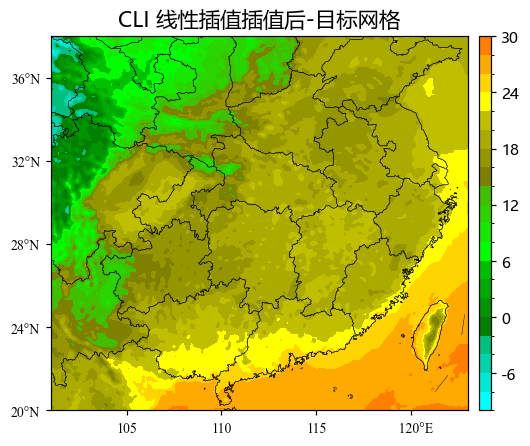

In [7]:
from cli.interpolation_grid_grid_cli import InterpolationGridGridCli

input_path = str(DATA_DIR / "2026100900.024.nc")
out_linear = str(DATA_DIR / "cli_linear_out.m4")

# 1) 调度写盘
rc = InterpolationGridGridCli.call(
    module="linear",
    grid=input_path,
    output=out_linear,
    glon="101.0, 123.0, 0.01",
    glat="20.0, 38.0, 0.01",
    outer_value=0.0,
    grid_type="nc",
)

# 2) 读输入场与输出场（输入场绘图只绘插值范围）
grid = meb.read_griddata_from_nc(input_path)
grd_in = grid.sel(lon=slice(101.0, 123.0), lat=slice(20.0, 38.0))
result = meb.read_griddata_from_micaps4(out_linear)
print("写出 →", out_linear)
print(result)

cmap, clevs = get_cmap_and_clevs_by_element_name("temp")
pcolormesh_2d_grid(
    grd_in, title="CLI 插值前-源场",
    cmap=cmap, clevs=clevs, dpi=110, show=True,
)
pcolormesh_2d_grid(
    result, title="CLI 线性插值插值后-目标网格",
    cmap=cmap, clevs=clevs, dpi=110, show=True,
)

### 8.2 TranRegridCli

写出 → D:\workspace\test\00temp\interpolation_grid_grid\resource\data\cli_landsea_bilinear_out.nc
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 1801,
                           lon: 2201)> Size: 16MB
array([[[[[[19.8  , 19.7  , 19.6  , ..., 28.72 , 28.71 , 28.7  ],
           [19.68 , 19.582, 19.484, ..., 28.702, 28.691, 28.68 ],
           [19.56 , 19.464, 19.368, ..., 28.684, 28.672, 28.66 ],
           ...,
           [-8.86 , -8.74 , -8.62 , ..., 19.4  , 19.4  , 19.4  ],
           [-8.93 , -8.8  , -8.67 , ..., 19.4  , 19.4  , 19.4  ],
           [-9.   , -8.86 , -8.72 , ..., 19.4  , 19.4  , 19.4  ]]]]]],
      shape=(1, 1, 1, 1, 1801, 2201), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 14kB 20.0 20.01 20.02 20.03 ... 37.98 37.99 38.0
  * lon      (lon) float64 18kB 101.0 101.0 101.0 101.0 ... 1

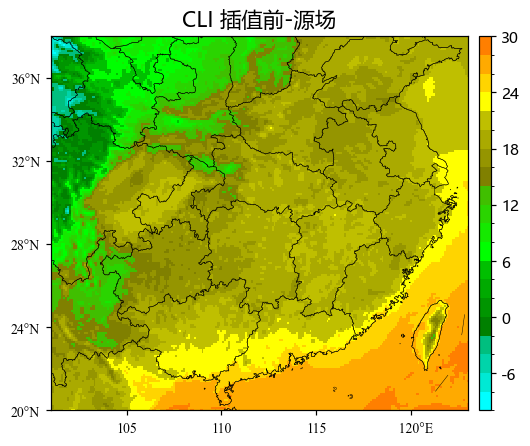

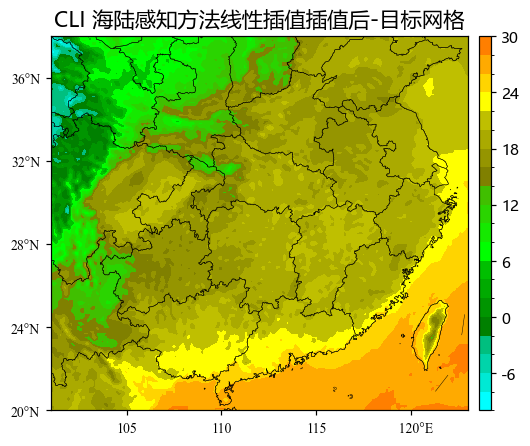

In [8]:
from cli.tran_regrid import TranRegridCli

input_path = str(DATA_DIR / "2026100900.024.nc")
target_grid_path = str(DATA_DIR / "target_grid.nc")
out_landsea = str(DATA_DIR / "cli_landsea_bilinear_out.nc")

# 1) 调度写盘
TranRegridCli.call(
    input_path=input_path,
    target_grid_path=target_grid_path,
    output_path=out_landsea,
    land_sea_mask_path=None,
    regrid_mode="bilinear",
    extrapolation_mode="nan",
)

# 2) 读输入场与输出场（输入场绘图只绘插值范围）
grid = meb.read_griddata_from_nc(input_path)
grd_in = grid.sel(lon=slice(101.0, 123.0), lat=slice(20.0, 38.0))
result = meb.read_griddata_from_nc(out_landsea)
print("写出 →", out_landsea)
print(result)

pcolormesh_2d_grid(
    grd_in, title="CLI 插值前-源场",
    cmap=cmap, clevs=clevs, dpi=110, show=True,
)
pcolormesh_2d_grid(
    result, title="CLI 海陆感知方法线性插值插值后-目标网格",
    cmap=cmap, clevs=clevs, dpi=110, show=True,
)